# Notes
- Label Encoding, Target Encoding, Frekans Encoding yaptıktan sonra lineer modellerin büyük sayılı etiket alanın fiyatınında daha büyük olması gerekir gibi bir mantık kurma riski vardır
- bunun için bu encode yöntemleri ile birlikte ağaç tabanlı modeller kullanılır. lineer modeller ve yapay sinir ağları tercih edilmez
- Hedef değişkenle arasında çok yüksek korelasyon olan nitelikleri eledim. (line item value, line item quantity)

# Import Libs

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split


import warnings 
warnings.filterwarnings("ignore")

# Import Dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/irakozekelly/supply-chain-shipment-pricing-dataset/Supply_Chain_Shipment_Pricing_Dataset.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   id                            10324 non-null  int64  
 1   project code                  10324 non-null  object 
 2   pq #                          10324 non-null  object 
 3   po / so #                     10324 non-null  object 
 4   asn/dn #                      10324 non-null  object 
 5   country                       10324 non-null  object 
 6   managed by                    10324 non-null  object 
 7   fulfill via                   10324 non-null  object 
 8   vendor inco term              10324 non-null  object 
 9   shipment mode                 9964 non-null   object 
 10  pq first sent to client date  10324 non-null  object 
 11  po sent to vendor date        10324 non-null  object 
 12  scheduled delivery date       10324 non-null  object 
 13  d

remove --> id,
target encoding --> project code


In [3]:
df.isnull().sum().sort_values(ascending=False)

dosage                          1736
shipment mode                    360
line item insurance (usd)        287
id                                 0
project code                       0
country                            0
managed by                         0
po / so #                          0
pq #                               0
vendor inco term                   0
pq first sent to client date       0
po sent to vendor date             0
scheduled delivery date            0
delivered to client date           0
delivery recorded date             0
fulfill via                        0
asn/dn #                           0
sub classification                 0
product group                      0
molecule/test type                 0
vendor                             0
brand                              0
dosage form                        0
unit of measure (per pack)         0
item description                   0
line item quantity                 0
line item value                    0
u

In [4]:
df.head(20)

,id,project code,pq #,po / so #,asn/dn #,country,managed by,fulfill via,vendor inco term,shipment mode,...,unit of measure (per pack),line item quantity,line item value,pack price,unit price,manufacturing site,first line designation,weight (kilograms),freight cost (usd),line item insurance (usd)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,30,19,551.00,29.00,0.97,Ranbaxy Fine Chemicals LTD,True,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,240,1000,6200.00,6.20,0.03,"Aurobindo Unit III, India",True,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,100,500,40000.00,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,True,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,31920,127360.80,3.99,0.07,"Ranbaxy, Paonta Shahib, India",True,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,38000,121600.00,3.20,0.05,"Aurobindo Unit III, India",True,7590,45450.08,NaN
5,23,112-NG-T01,Pre-PQ Process,SCMS-87,ASN-57,Nigeria,PMO - US,Direct Drop,EXW,Air,...,240,416,2225.60,5.35,0.02,"Aurobindo Unit III, India",True,504,5920.42,NaN
6,44,110-ZM-T01,Pre-PQ Process,SCMS-139,ASN-130,Zambia,PMO - US,Direct Drop,DDU,Air,...,90,135,4374.00,32.40,0.36,MSD South Granville Australia,True,328,Freight Included in Commodity Cost,NaN
7,45,109-TZ-T01,Pre-PQ Process,SCMS-140,ASN-94,Tanzania,PMO - US,Direct Drop,EXW,Air,...,60,16667,60834.55,3.65,0.06,"Aurobindo Unit III, India",True,1478,6212.41,NaN
8,46,112-NG-T01,Pre-PQ Process,SCMS-156,ASN-93,Nigeria,PMO - US,Direct Drop,EXW,Air,...,60,273,532.35,1.95,0.03,"Aurobindo Unit III, India",False,See ASN-93 (ID#:1281),See ASN-93 (ID#:1281),NaN
9,47,110-ZM-T01,Pre-PQ Process,SCMS-165,ASN-199,Zambia,PMO - US,Direct Drop,CIP,Air,...,120,2800,115080.00,41.10,0.34,ABBVIE (Abbott) St. P'burg USA,True,643,Freight Included in Commodity Cost,NaN


# EDA

In [5]:
print(f"Proje kodu:{df["project code"].nunique()}")
print(f"Talep no:{df["pq #"].nunique()}")
print(f"Satış no:{df["po / so #"].nunique()}")
print(f"Teslimat bildirim no:{df["asn/dn #"].nunique()}")

Proje kodu:142
Talep no:1237
Satış no:6233
Teslimat bildirim no:7030


Label Encoding --> Proje kodu 

Remove --> pq #, po / so #,asn/dn #

In [6]:
print(f"Ulkeler: {df["country"].nunique()}")
print("===============================================================================================================")
print(f"Yonetici Kurumlar:{df["managed by"].unique()} {df['managed by'].value_counts()}")
print("===============================================================================================================")
print(f"Gonderim Sekli: {df["fulfill via"].nunique()} {df["fulfill via"].unique()} {df['fulfill via'].value_counts()}")
print("===============================================================================================================")
print(f"Uluslararası Teslim Sekli: {df["vendor inco term"].nunique()} {df["vendor inco term"].value_counts()}")
print("===============================================================================================================")
print(f"Tasima Modu: {df["shipment mode"].nunique()} {df["shipment mode"].unique()} {df['shipment mode'].value_counts()}")
print("===============================================================================================================")
print(f"Urun Grubu: {df["product group"].nunique()} {df["product group"].unique()} {df['product group'].value_counts()}")
print("===============================================================================================================")
print(f"Alt Grup: {df["sub classification"].nunique()} {df["sub classification"].unique()} {df['sub classification'].value_counts()}")
print("===============================================================================================================")
print(f"Firma: {df["vendor"].nunique()}")
print("===============================================================================================================")
print(f"Urun Tanımı: {df["item description"].nunique()}")
print("===============================================================================================================")
print(f"Test Tipi: {df["molecule/test type"].nunique()}")
print("===============================================================================================================")
print(f"Marka: {df["brand"].nunique()}")
print("===============================================================================================================")
print(f"Dozajlar: {df["dosage"].nunique()} {df["dosage"].unique()}")
print("===============================================================================================================")
print(f"Dozaj Formu: {df["dosage form"].nunique()} {df["dosage form"].unique()}")
print("===============================================================================================================")
print(f"Paket Bası Tablet Sayısı: {df["unit of measure (per pack)"].nunique()} {df["unit of measure (per pack)"].unique()}")
print("===============================================================================================================")
print(f"Üretim Tesisi: {df["manufacturing site"].nunique()}")

Ulkeler: 43
Yonetici Kurumlar:['PMO - US' 'South Africa Field Office' 'Haiti Field Office'
 'Ethiopia Field Office'] managed by
PMO - US                     10265
South Africa Field Office       57
Haiti Field Office               1
Ethiopia Field Office            1
Name: count, dtype: int64
Gonderim Sekli: 2 ['Direct Drop' 'From RDC'] fulfill via
From RDC       5404
Direct Drop    4920
Name: count, dtype: int64
Uluslararası Teslim Sekli: 8 vendor inco term
N/A - From RDC    5404
EXW               2778
DDP               1443
FCA                397
CIP                275
DDU                 15
DAP                  9
CIF                  3
Name: count, dtype: int64
Tasima Modu: 4 ['Air' nan 'Truck' 'Air Charter' 'Ocean'] shipment mode
Air            6113
Truck          2830
Air Charter     650
Ocean           371
Name: count, dtype: int64
Urun Grubu: 5 ['HRDT' 'ARV' 'ACT' 'MRDT' 'ANTM'] product group
ARV     8550
HRDT    1728
ANTM      22
ACT       16
MRDT       8
Name: count, dtype: in

label encoding -->tüm kategorik verilere uygulanacak

In [7]:
df['freight cost (usd)'].value_counts()
print(f"Kategoriklerin Toplam Sayısı:{df[pd.to_numeric(df['freight cost (usd)'], errors='coerce').isna()]['freight cost (usd)'].value_counts().sum()}")
print("==============================================================================================================================")
print(f"Kategoriklerin Tek Tek Sayısı:{df[pd.to_numeric(df['freight cost (usd)'], errors='coerce').isna()]['freight cost (usd)'].value_counts()}")

Kategoriklerin Toplam Sayısı:4126
Kategoriklerin Tek Tek Sayısı:freight cost (usd)
Freight Included in Commodity Cost    1442
Invoiced Separately                    239
See DN-304 (ID#:10589)                  16
See ASN-32231 (ID#:13648)               14
See ASN-31750 (ID#:19272)               14
                                      ... 
See DN-4011 (ID#:84426)                  1
See DN-3903 (ID#:86131)                  1
See DN-3867 (ID#:84968)                  1
See DN-4016 (ID#:84996)                  1
See DN-3866 (ID#:85519)                  1
Name: count, Length: 1301, dtype: int64


paket ucretine dahil yada değil gibi sınıflandırılabilir

In [8]:
print(f"Kategoriklerin Toplam Sayısı:{df[pd.to_numeric(df['weight (kilograms)'], errors='coerce').isna()]['weight (kilograms)'].value_counts().sum()}")
print("==============================================================================================================================")
print(f"Kategoriklerin Tek Tek Sayısı:{df[pd.to_numeric(df['weight (kilograms)'], errors='coerce').isna()]['weight (kilograms)'].value_counts()}")

Kategoriklerin Toplam Sayısı:3952
Kategoriklerin Tek Tek Sayısı:weight (kilograms)
Weight Captured Separately    1507
See DN-304 (ID#:10589)          16
See ASN-32231 (ID#:13648)       14
See ASN-31750 (ID#:19272)       14
See ASN-28279 (ID#:13547)       13
                              ... 
See DN-4052 (ID#:85005)          1
See DN-4011 (ID#:84426)          1
See DN-3903 (ID#:86131)          1
See DN-3867 (ID#:84968)          1
See DN-4016 (ID#:84996)          1
Name: count, Length: 1300, dtype: int64


In [9]:
print(df["po sent to vendor date"].isna().sum())
print(df["scheduled delivery date"].isna().sum())
print(df["delivered to client date"].isna().sum())
print(df["delivery recorded date"].isna().sum())
print(df["pq first sent to client date"].isna().sum())

0
0
0
0
0


In [10]:
print(df["pq first sent to client date"].value_counts())

pq first sent to client date
Pre-PQ Process       2476
9/11/2014             205
Date Not Captured     205
7/11/2013             173
4/30/2014             123
                     ... 
1/23/2013               1
12/19/2014              1
8/2/2011                1
2/2/2012                1
8/29/2013               1
Name: count, Length: 765, dtype: int64


# GEDA

In [11]:
df.describe()

,id,unit of measure (per pack),line item quantity,line item value,pack price,unit price,line item insurance (usd)
count,10324.000000,10324.000000,10324.000000,1.032400e+04,10324.000000,10324.000000,10037.000000
mean,51098.968229,77.990895,18332.534870,1.576506e+05,21.910241,0.611701,240.117626
std,31944.332496,76.579764,40035.302961,3.452921e+05,45.609223,3.275808,500.190568
min,1.000000,1.000000,1.000000,0.000000e+00,0.000000,0.000000,0.000000
25%,12795.750000,30.000000,408.000000,4.314593e+03,4.120000,0.080000,6.510000
50%,57540.500000,60.000000,3000.000000,3.047147e+04,9.300000,0.160000,47.040000
75%,83648.250000,90.000000,17039.750000,1.664471e+05,23.592500,0.470000,252.400000
max,86823.000000,1000.000000,619999.000000,5.951990e+06,1345.640000,238.650000,7708.440000


<Axes: >

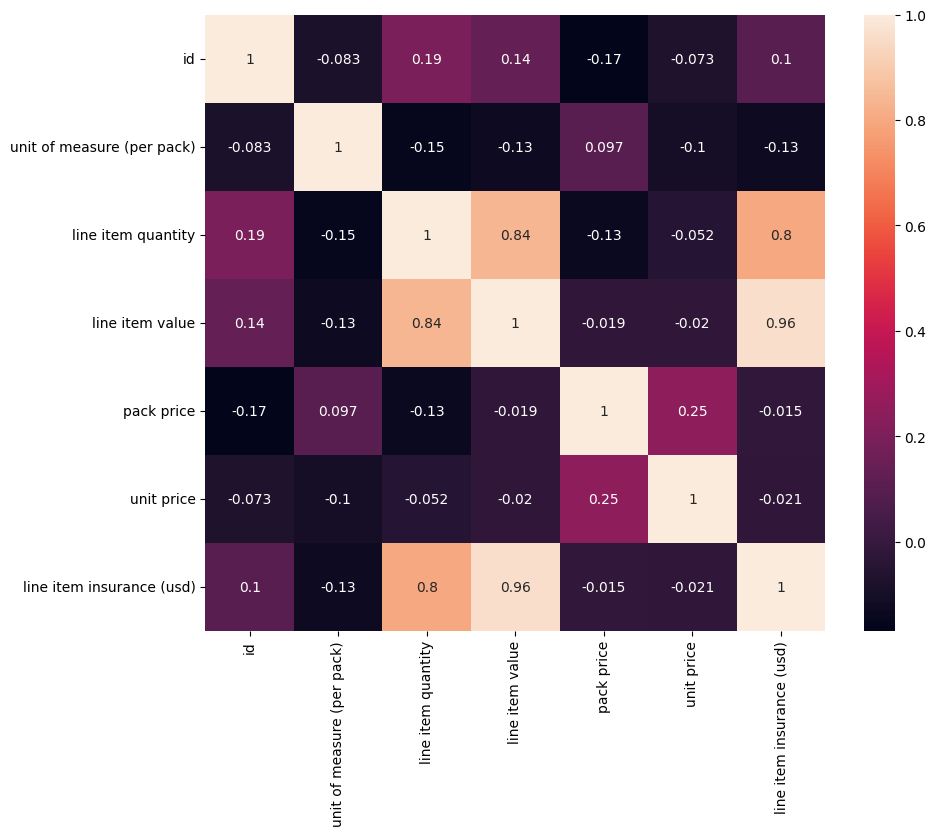

In [12]:
numeric_cols = df.select_dtypes(include=["number"])
matrix = numeric_cols.corr()

plt.figure(figsize=(10,8))
sns.heatmap(matrix,annot = True)

- Line item value ve line item quantity hedef niteliğin neredeyse aynısını yansıtır bu yüzden eleme yapacağız

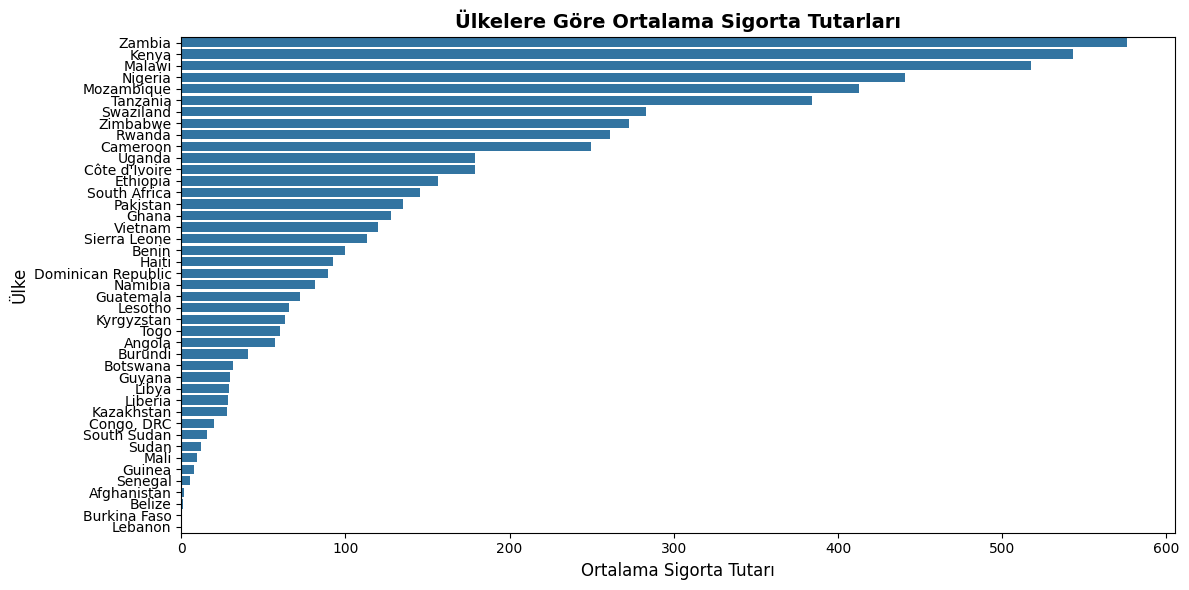

In [13]:
country_insurance = (
    df.groupby('country')['line item insurance (usd)']
    .mean()
    .reset_index()
    .sort_values(by='line item insurance (usd)', ascending=False)
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=country_insurance,
    x='line item insurance (usd)',
    y='country'
)

plt.title('Ülkelere Göre Ortalama Sigorta Tutarları', fontsize=14, fontweight='bold')
plt.xlabel('Ortalama Sigorta Tutarı', fontsize=12)
plt.ylabel('Ülke', fontsize=12)
plt.tight_layout()
plt.show()

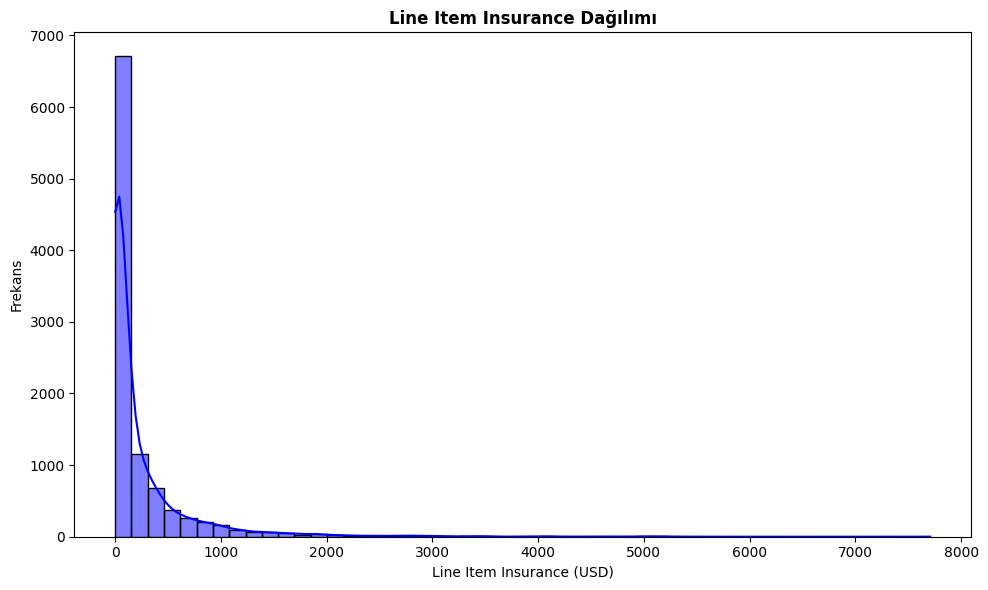

In [14]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df['line item insurance (usd)'].dropna(), kde=True, color='blue', bins=50
)
plt.title('Line Item Insurance Dağılımı', fontsize=12, fontweight='bold')
plt.xlabel('Line Item Insurance (USD)', fontsize=10)
plt.ylabel('Frekans', fontsize=10)

plt.tight_layout()
plt.show()

# Feature Engineering

In [15]:
def categorize_freight(val):
  val_str = str(val).strip()
  if "Freight Included" in val_str:
    return "Included_in_Cost"
  elif "Invoiced Separately" in val_str:
    return "Invoiced_Separately"
  elif "See DN-" in val_str or "See ASN-" in val_str:
    return "Referenced_Document"
  else:
    try:
      float(val_str)
      return "Numeric_Cost"
    except:
      return "Unknown"

df["freight_payment_type"] = df["freight cost (usd)"].apply(categorize_freight)
print(df["freight_payment_type"].value_counts())

freight_payment_type
Numeric_Cost           6198
Referenced_Document    2445
Included_in_Cost       1442
Invoiced_Separately     239
Name: count, dtype: int64


# Feature Selection

In [16]:
remove_cols = ["id","pq #","po / so #","asn/dn #","weight (kilograms)","freight cost (usd)",
               "po sent to vendor date","scheduled delivery date","delivered to client date",
               "delivery recorded date","pq first sent to client date"]
df.drop(remove_cols, inplace=True, axis = 1)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   project code                10324 non-null  object 
 1   country                     10324 non-null  object 
 2   managed by                  10324 non-null  object 
 3   fulfill via                 10324 non-null  object 
 4   vendor inco term            10324 non-null  object 
 5   shipment mode               9964 non-null   object 
 6   product group               10324 non-null  object 
 7   sub classification          10324 non-null  object 
 8   vendor                      10324 non-null  object 
 9   item description            10324 non-null  object 
 10  molecule/test type          10324 non-null  object 
 11  brand                       10324 non-null  object 
 12  dosage                      8588 non-null   object 
 13  dosage form                 103

# Train Test Split

In [17]:
X = df.drop(columns=["line item insurance (usd)"])
y = df["line item insurance (usd)"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)